# Regularisation: decision tree limits, Ridge and Lasso

**Research question:** what factors can predict whether or not adolescents cross the clinical threshold for depression according to the BDI-II?

This notebook applies the Week 7B material (regularisation) to the project data in two parts:
1. **Regularising decision trees** (`max_depth`, `min_samples_leaf`) for the binary `depressed` target, continuing from `decision_tree.ipynb`.
2. **Ridge (L2) and Lasso (L1)** for the BDI-II total score (`bdi_total`), continuing from the linear regression in `modelling.ipynb`.

Regularisation discourages overly complex models, which can reduce overfitting.

---
## Step 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import recall_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

RANDOM_STATE = 42

---
## Step 2. Load data and split

The same seven features and the same split (20% test, seed 42) as the other model notebooks.

In [2]:
df = pd.read_csv("../data/processed/model_ready.csv")

feature_cols = [
    "screen_time_index", "est_leisure_screen_hours", "sex_binary",
    "sleep_quality_index", "avg_sleep_hours",
    "midsleep_weekend_hours", "social_jetlag_hours",
]
X = df[feature_cols]
y = df["depressed"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
baseline_acc = (y_test == 0).mean()
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print(f"Baseline (always 'not depressed'): {baseline_acc:.3f}")

Training rows: 3848 | Test rows: 962
Baseline (always 'not depressed'): 0.848


---
## Step 3. Regularising decision trees

A tree can be constrained with:
- `max_depth`: limit the number of levels
- `min_samples_leaf`: every leaf must contain at least this many training adolescents

These limits can reduce overfitting, although a simpler tree is not guaranteed to perform better on every split.

In [3]:
# Each entry: (label, settings passed to DecisionTreeClassifier)
tree_settings = [
    ("Unrestricted", {}),
    ("Depth 3", {"max_depth": 3}),
    ("Depth 5, leaf size 5", {"max_depth": 5, "min_samples_leaf": 5}),
    ("Depth 3, leaf size 10", {"max_depth": 3, "min_samples_leaf": 10}),
]

tree_rows = []
for name, settings in tree_settings:
    model = DecisionTreeClassifier(random_state=RANDOM_STATE, **settings)
    model.fit(X_train, y_train)
    tree_rows.append({
        "Model": name,
        "Leaves": model.get_n_leaves(),               # fewer leaves = simpler tree
        "Depth reached": model.get_depth(),
        "Training accuracy": model.score(X_train, y_train),
        "Test accuracy": model.score(X_test, y_test),
        "Test recall (depressed)": recall_score(y_test, model.predict(X_test)),
    })

tree_table = pd.DataFrame(tree_rows)
tree_table.round(3)

,Model,Leaves,Depth reached,Training accuracy,Test accuracy,Test recall (depressed)
0,Unrestricted,670,25,1.000,0.771,0.308
1,Depth 3,8,3,0.840,0.846,0.048
2,"Depth 5, leaf size 5",29,5,0.849,0.849,0.089
3,"Depth 3, leaf size 10",8,3,0.840,0.846,0.048


## **Explanation: reading the tree regularisation table**

Each row is a tree grown with different limits. All test figures are on the same 962 adolescents, where the baseline of always predicting "not depressed" scores **0.848**.

- **Leaves** shows how complex the tree is (how many separate rules it made). **Depth reached** shows how many questions in a row it ended up asking.
- **Training vs test accuracy:** the gap between them is the overfitting warning sign.
- **Recall (depressed):** the share of the 146 real cases above the threshold that the tree catches.

**Row by row**
- **Unrestricted (670 leaves, depth 25):** nothing stops the tree, so it keeps splitting until every leaf is pure. It gets **every** training adolescent right (1.000), but only 0.771 on the test set, **below the baseline**. The 0.229 gap is clear overfitting: hundreds of leaves are rules built around one or two individual adolescents. It catches the most real cases (recall 0.308), but only by flagging many adolescents who are not depressed, which is why its accuracy is the worst.
- **Depth 3 (8 leaves):** 0.840 training, 0.846 test, almost no gap, so no overfitting. But it catches only 7 of 146 real cases (recall 0.048). It has generalised, but to a rule that is very close to "predict not depressed".
- **Depth 5, leaf size 5 (29 leaves):** training and test are both 0.849, the highest test accuracy in the table and just above the baseline (by one adolescent out of 962). Recall is 0.089 (13 cases).
- **Depth 3, leaf size 10 (8 leaves):** identical to plain depth 3. Every leaf of the depth-3 tree already holds at least 13 adolescents, so a minimum of 10 changes nothing.

**What this shows**
1. **Regularisation removes the overfitting.** Every constrained tree closes the train/test gap and scores far better on new adolescents than the unrestricted tree (0.846–0.849 vs 0.771).
2. **But it cannot create signal that is not there.** The constrained trees only match the baseline. With seven features and a 1-in-6 class, the tree cannot find many groups where depressed adolescents are the majority.
3. **The differences between the three constrained trees are tiny** (0.846 vs 0.849 is 3 adolescents out of 962), so none is clearly better than the others.

---
## Step 4. Ridge and Lasso: penalising coefficients

For linear regression, regularisation adds a penalty to the data-fitting loss:

**Objective = loss + alpha × penalty**

- **Ridge (L2):** penalises squared coefficients and shrinks them all towards zero.
- **Lasso (L1):** penalises absolute coefficients and can set some coefficients **exactly to zero** (feature selection).

`depressed` is binary, so it is not a regression target. For this part the target is `bdi_total` (the continuous BDI-II score, 0–63), as in `modelling.ipynb`, with the same seven features and the same split.

In [4]:
y_reg = df["bdi_total"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X, y_reg, test_size=0.2, random_state=RANDOM_STATE
)
print("Training rows:", len(Xr_train), "| Test rows:", len(Xr_test))

Training rows: 3848 | Test rows: 962


---
## Step 5. Compare ordinary linear regression, Ridge and Lasso

The features are **standardised inside each pipeline**. The penalty depends on coefficient size, and coefficient size depends on a feature's units (hours, a 1–6 index, 0/1 for sex), so without scaling the penalty would treat features unfairly.

`alpha` controls the penalty strength; larger values mean stronger regularisation. The alpha values are the same as in the Week 7B notebook.

> scikit-learn scales the Ridge and Lasso objectives differently, so the same `alpha` number does not mean the same strength in both. Compare each model with plain linear regression, not alpha with alpha.

In [5]:
models = {
    "Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
    "+Ridge (alpha=50)": make_pipeline(StandardScaler(), Ridge(alpha=50)),
    "+Lasso (alpha=1)": make_pipeline(StandardScaler(), Lasso(alpha=1, max_iter=10000)),
}

score_rows, coefficient_rows = [], []
for name, model in models.items():
    model.fit(Xr_train, yr_train)
    # R² = share of the target's variation explained (1 = perfect)
    score_rows.append({
        "Model": name,
        "Training R²": model.score(Xr_train, yr_train),
        "Test R²": model.score(Xr_test, yr_test),
    })
    # model[-1] is the last pipeline step (the regression model); coef_ holds its coefficients
    for feature, coef in zip(feature_cols, model[-1].coef_):
        coefficient_rows.append({"Model": name, "Feature": feature, "Coefficient": coef})

display(pd.DataFrame(score_rows).round(3))
coef_df = pd.DataFrame(coefficient_rows)
coef_pivot = coef_df.pivot(index="Feature", columns="Model", values="Coefficient")
coef_pivot = coef_pivot[list(models)]   # keep column order: linear, Ridge, Lasso
display(coef_pivot.loc[feature_cols].round(3))

,Model,Training R²,Test R²
0,Linear regression,0.209,0.22
1,+Ridge (alpha=50),0.209,0.22
2,+Lasso (alpha=1),0.163,0.17


Model,Linear regression,+Ridge (alpha=50),+Lasso (alpha=1)
Feature,,,
screen_time_index,1.123,0.981,0.000
est_leisure_screen_hours,-0.624,-0.484,0.000
sex_binary,1.596,1.582,0.725
sleep_quality_index,2.236,2.211,1.630
avg_sleep_hours,-0.692,-0.703,-0.335
midsleep_weekend_hours,0.413,0.397,0.000
social_jetlag_hours,0.067,0.079,0.000


## **Explanation: reading the R² and coefficient tables**

**R² table**
- **Linear regression: 0.209 training, 0.220 test.** These match `modelling.ipynb` exactly. Standardising the features changes the size of the coefficients, but not the predictions, so R² is unchanged.
- **Ridge (alpha = 50): almost identical** (0.209 / 0.220).
- **Lasso (alpha = 1): lower**, 0.163 training and 0.170 test.
- Training and test R² are close for all three, so **none of them is overfitting**. The linear model was not overfitting to begin with, so regularisation has little to fix here. With 3,848 training adolescents and only seven features, there is far more data than the model needs to estimate seven coefficients reliably.

**Coefficient table** (standardised features, so each coefficient is the change in predicted BDI-II score for a **one-standard-deviation** increase in that feature)
- **`sleep_quality_index` (+2.24) is the strongest predictor**, followed by **`sex_binary` (+1.60)**. Poorer sleep quality and being a girl go with higher BDI-II scores.
- **This order differs from `modelling.ipynb`**, where `sex_binary` had the largest coefficient (+3.19). That coefficient was per one-unit change, and for sex one unit is the whole Boy→Girl difference. Here, one standard deviation of `sex_binary` is about 0.5, so +3.19 × 0.5 ≈ +1.60. Standardising puts every feature on the same scale, which makes them comparable, and on that scale sleep quality matters most.
- **`avg_sleep_hours` (−0.69)** and **`est_leisure_screen_hours` (−0.62)** have negative coefficients: they lower the predicted score. The second one is suspicious (see the alpha investigation below).
- **Ridge** shrinks every coefficient slightly, but none becomes zero. The biggest change is in the two screen-time features: `screen_time_index` (1.12 → 0.98) and `est_leisure_screen_hours` (−0.62 → −0.48).
- **Lasso** sets **four coefficients to exactly 0**: `screen_time_index`, `est_leisure_screen_hours`, `midsleep_weekend_hours` and `social_jetlag_hours`. Only sleep quality (+1.63), sex (+0.73) and average sleep (−0.33) are kept. At this strength Lasso has removed screen time from the model entirely, and test R² drops from 0.220 to 0.170, so alpha = 1 is too strong for this dataset. The alpha investigation below shows the full range.

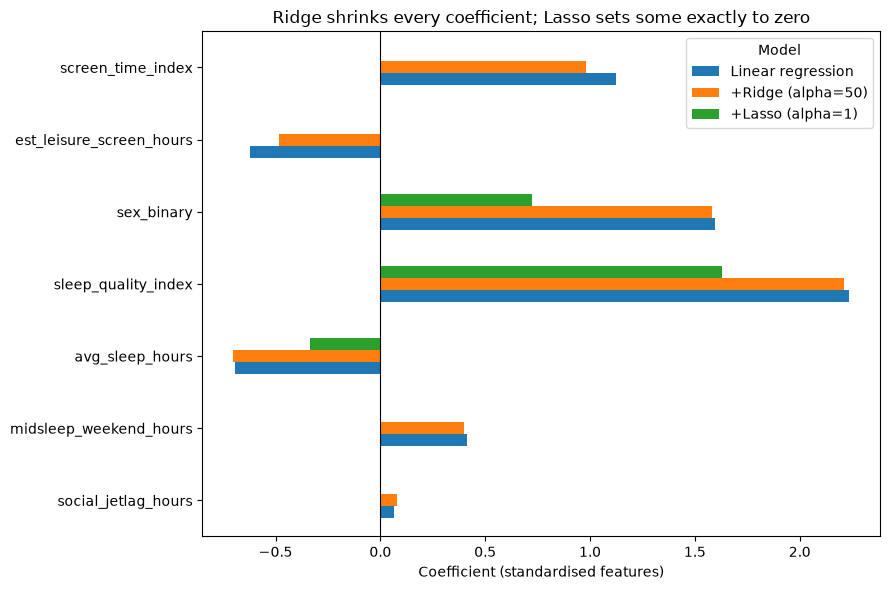

In [6]:
ax = coef_pivot.loc[feature_cols[::-1]].plot(kind="barh", figsize=(9, 6))   # keep the feature order top to bottom
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (standardised features)")
ax.set_ylabel("")
ax.set_title("Ridge shrinks every coefficient; Lasso sets some exactly to zero")
plt.tight_layout()
plt.show()

## **Explanation: the coefficient bar chart**

This is the coefficient table as a picture. Each feature has three bars: linear regression, Ridge and Lasso.

- **The black vertical line is zero.** Bars to the right raise the predicted BDI-II score; bars to the left (`avg_sleep_hours`, `est_leisure_screen_hours`) lower it.
- **Bar length** shows how strongly each feature is linked to the score. `sleep_quality_index` and `sex_binary` have the longest bars.
- **Linear and Ridge bars are almost the same length:** alpha = 50 is a weak penalty when there are 3,848 training adolescents, because the data-fitting loss grows with the number of adolescents while the penalty does not.
- **The Lasso bars are missing for four features** (both screen-time features, weekend midsleep and social jetlag). That is Lasso's feature selection: those coefficients are exactly zero.

---
## Step 6. Investigate the penalty strength

Each line is one feature's coefficient as `alpha` increases (left to right, on a log scale where each tick is ×10). The two panels use different alpha ranges because the two objectives are scaled differently.

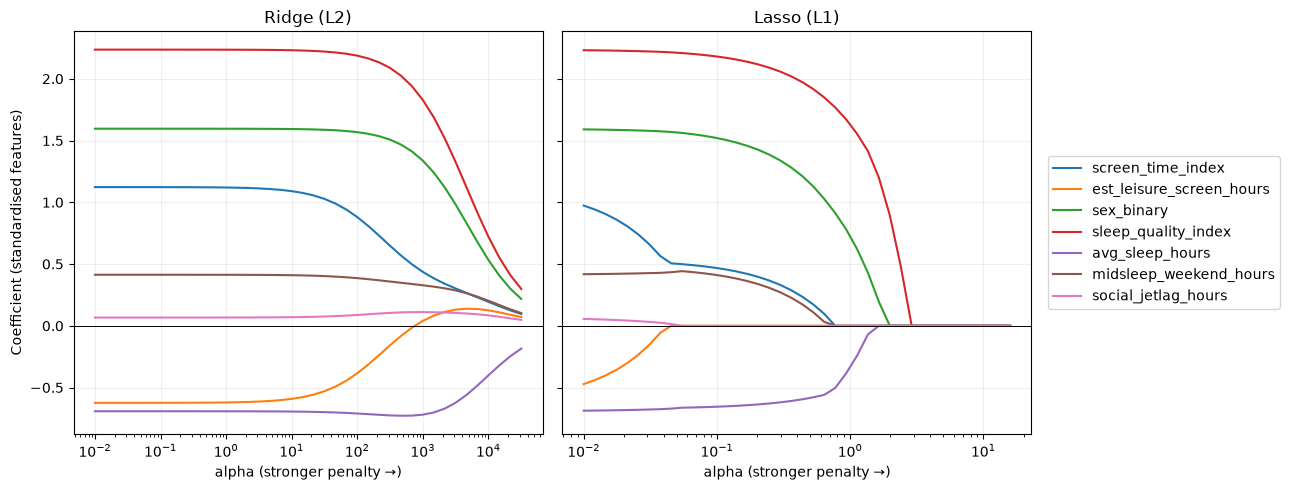

In [7]:
# Separate alpha ranges, because the two objectives are scaled differently
ridge_alphas = np.logspace(-2, 4.5, 40)
lasso_alphas = np.logspace(-2, 1.2, 40)

ridge_path = [make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xr_train, yr_train)[-1].coef_
              for a in ridge_alphas]
lasso_path = [make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=20000)).fit(Xr_train, yr_train)[-1].coef_
              for a in lasso_alphas]
ridge_path, lasso_path = np.asarray(ridge_path), np.asarray(lasso_path)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for j, feature in enumerate(feature_cols):
    axes[0].plot(ridge_alphas, ridge_path[:, j], label=feature)
    axes[1].plot(lasso_alphas, lasso_path[:, j], label=feature)
for ax, title in zip(axes, ["Ridge (L2)", "Lasso (L1)"]):
    ax.set_xscale("log")
    ax.set_xlabel("alpha (stronger penalty →)")
    ax.set_title(title)
    ax.axhline(0, color="black", linewidth=0.7)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Coefficient (standardised features)")
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.tight_layout()
plt.show()

In [8]:
# The alpha at which each feature's Lasso coefficient first reaches exactly zero
first_zero = {}
for j, feature in enumerate(feature_cols):
    zero_idx = np.where(lasso_path[:, j] == 0)[0]
    first_zero[feature] = lasso_alphas[zero_idx[0]] if len(zero_idx) else np.nan
pd.Series(first_zero, name="Lasso: alpha where coefficient reaches 0").sort_values().round(3)

est_leisure_screen_hours    0.045
social_jetlag_hours         0.055
midsleep_weekend_hours      0.771
screen_time_index           0.771
avg_sleep_hours             1.642
sex_binary                  1.984
sleep_quality_index         2.894
Name: Lasso: alpha where coefficient reaches 0, dtype: float64

In [9]:
# Correlations behind the drop-out order: the two pairs of related features
X[feature_cols].corr().round(2)

,screen_time_index,est_leisure_screen_hours,sex_binary,sleep_quality_index,avg_sleep_hours,midsleep_weekend_hours,social_jetlag_hours
screen_time_index,1.00,0.94,0.01,0.09,-0.26,0.29,0.18
est_leisure_screen_hours,0.94,1.00,-0.02,0.07,-0.23,0.26,0.16
sex_binary,0.01,-0.02,1.00,0.20,-0.08,-0.09,-0.08
sleep_quality_index,0.09,0.07,0.20,1.00,-0.32,0.12,0.02
avg_sleep_hours,-0.26,-0.23,-0.08,-0.32,1.00,-0.52,-0.16
midsleep_weekend_hours,0.29,0.26,-0.09,0.12,-0.52,1.00,0.84
social_jetlag_hours,0.18,0.16,-0.08,0.02,-0.16,0.84,1.00


## **Explanation: the coefficient path plots**

**Left: Ridge (L2)**
- At small alpha (left edge) every coefficient equals its linear-regression value.
- As alpha grows, the lines **curve smoothly towards zero** but never reach it. Very little changes until alpha is in the hundreds, which again shows that this model, with plenty of data and few features, does not need much regularisation.
- The **two screen-time features change first** (from about alpha = 50). `screen_time_index` falls and `est_leisure_screen_hours` rises from −0.62 towards zero and then **crosses to slightly positive** around alpha ≈ 1,000. Ridge spreads the shared effect of two correlated features across both of them, so the "screen time lowers the score" sign of `est_leisure_screen_hours` does not survive.
- At the far right (alpha ≈ 30,000) every line is squeezed close to zero: the penalty dominates and the model barely uses any feature.

**Right: Lasso (L1)**
The lines **hit zero one after another and stay there**. The drop-out table gives the order:
1. **`est_leisure_screen_hours`** (alpha ≈ 0.05) and **`social_jetlag_hours`** (≈ 0.06) drop out almost immediately.
2. **`screen_time_index`** and **`midsleep_weekend_hours`** (≈ 0.77).
3. **`avg_sleep_hours`** (≈ 1.64), then **`sex_binary`** (≈ 1.98).
4. **`sleep_quality_index`** survives longest (≈ 2.89). It is the strongest predictor of BDI-II score.

**Why those two drop first: multicollinearity again**
The correlation table explains it:
- `est_leisure_screen_hours` and `screen_time_index` correlate at **0.94**: they are almost the same information.
- `social_jetlag_hours` and `midsleep_weekend_hours` correlate at **0.84**.

When two features carry nearly the same signal, Lasso keeps one and sets the other to zero, because the second adds almost nothing. On the Lasso plot, as `est_leisure_screen_hours` rises to zero, `screen_time_index` falls from about 1.0 to 0.5 **at the same time**: the two coefficients had been pushing against each other.

This also explains a puzzle in the coefficient table. With r = 0.94, it is odd that `screen_time_index` is positive (+1.12) while `est_leisure_screen_hours` is negative (−0.62). Two nearly identical features with **opposite signs** is a classic multicollinearity symptom: the model offsets one against the other. The negative coefficient for leisure screen hours should therefore not be read as "more leisure screen time lowers BDI scores". Both Ridge and Lasso remove it. This is the same problem found in `modelling.ipynb` (the raw screen-time and `sqi_*` items alongside their composite indexes). Lasso flags that each of these two pairs is still close to redundant, even after those fixes (all VIFs below 9).

**What this means for the model**
- Lasso at a small alpha (around 0.1) gives a **simpler model with the same test R²** (≈ 0.22) using five features instead of seven.
- Larger alpha → simpler model, but past alpha ≈ 0.5 the test R² starts to fall, so useful information is being removed.
- Choosing alpha properly needs data the final test set doesn't touch (cross-validation, Week 10).

---
## Step 7. Save results for the comparison notebook

The test-set predicted BDI-II scores from the three regression models are saved so `model_comparison.ipynb` can apply the clinical cut-off of 14 to them, as in `modelling.ipynb`.

In [10]:
import os
os.makedirs("../results", exist_ok=True)

reg_predictions = pd.DataFrame({"actual_bdi_total": yr_test.values}, index=yr_test.index)
for name, model in models.items():
    reg_predictions[name] = model.predict(Xr_test)
reg_predictions.to_csv("../results/regression_predictions.csv", index_label="row")

print("Saved ../results/regression_predictions.csv")

Saved ../results/regression_predictions.csv


---
## Summary of findings

- **Trees:** the unrestricted tree overfits badly (training 1.000, test 0.771, below the 0.848 baseline). `max_depth` and `min_samples_leaf` remove the overfitting (test 0.846–0.849), but the constrained trees only match the baseline and catch few real cases (recall 0.05–0.09).
- **Ridge and Lasso:** the linear regression for `bdi_total` was not overfitting (training R² 0.209, test 0.220), so Ridge changes almost nothing. Lasso at alpha = 1 removes four features and lowers test R² to 0.170, which is too strong.
- **Strongest predictors** (standardised): sleep quality (+2.24), then sex (+1.60) and average sleep hours (−0.69). Sleep quality is the last feature Lasso removes.
- The negative coefficient for `est_leisure_screen_hours` is a multicollinearity artefact (it offsets `screen_time_index`), and both penalties remove it.
- **Lasso's drop-out order** shows that `est_leisure_screen_hours` duplicates `screen_time_index` (r = 0.94) and `social_jetlag_hours` overlaps with `midsleep_weekend_hours` (r = 0.84), so one feature from each pair adds little.